# NDLAr-full Charge-Light Matching — v0.1 BACKBONE ONLY testing notebook

Runs the backbone-only pipeline **stage by stage** (front stage → Phase 2 large-cluster scan → V2 light rescue; **Phase 3 is intentionally NOT run**), keeping a per-hit t0 snapshot after every stage, then uses MC truth to **rank the seriously wrong TPCs** and provides per-TPC forensic cells so you can scan what happened at each stage.

Format mirrors `M5p1ReleaseVersion/vRelease5.ipynb`, but the engine is the packaged v0.1 backbone (`M5p1.first_stage_matching` + the valpha batch helpers), with the opt-in **intersection refinement** toggle.

## Front Stage (clustering [+ intersection refinement] + perceiver prediction + track/shower placement)

In [1]:
import os
import sys
import time
import importlib
import numpy as np
import h5py
import torch

# Locate the CLMatching_AlphaRelease clone (this notebook lives in
# <...>/CLMatching_v0.1_backboneOnly/testing/, the clone is its sibling).
_CWD = os.path.abspath(os.path.dirname("."))
_CANDIDATES = [
    os.path.join(_CWD, "..", "CLMatching_AlphaRelease"),
    os.path.join(_CWD, "CLMatching_AlphaRelease"),
    _CWD,
]
BASE_DIR = None
for _c in _CANDIDATES:
    if os.path.exists(os.path.join(_c, "M5p1", "first_stage_matching")):
        BASE_DIR = os.path.abspath(_c)
        break
if BASE_DIR is None:
    raise RuntimeError("Could not locate the CLMatching_AlphaRelease clone next to this notebook.")
print(f"BASE_DIR = {BASE_DIR}")

M5P1_DIR = os.path.join(BASE_DIR, "M5p1")
ML_DIR = os.path.join(BASE_DIR, "NewMLSection")
for _p in (M5P1_DIR, ML_DIR, BASE_DIR):
    while _p in sys.path:
        sys.path.remove(_p)
sys.path.insert(0, BASE_DIR)
sys.path.insert(1, ML_DIR)
sys.path.insert(2, M5P1_DIR)

from M5p1.first_stage_matching import (
    FirstStageConfig,
    load_first_stage_models,
    run_first_stage_charge_light_matching,
)
from M5p1.phase25_trial2_valpha_batch import (
    _build_namespace,
    _run_phase2,
    _summarize_v2_result,
    build_default_first_stage_config,
    build_default_v2_config,
)
from M5p1 import phase25_trial2_v2_light_rescue as v2
from v11_phased_matching import (
    snapshot_backbone_hits_v11,
    verify_backbone_hits_unchanged_v11,
)

N_TPCS = 70
WVFM_LEN = 1000
ADC_CLIP = 60780.0
T0_RESOLUTION = 5
NS_PER_TICK = 16.0

data_file = (
    "/global/cfs/cdirs/dunepro/people/abooth/nd-production/output/MiniProdN5/"
    "run-ndlar-flow/MiniProdN5p1_NDComplex_FHC.flow.full.sanddrift/FLOW/0000000/"
    "MiniProdN5p1_NDComplex_FHC.flow.full.sanddrift.0000001.FLOW.hdf5"
)
ev_id = 1

# ---------------- backbone-only toggles ----------------
REFINE_INTERSECTIONS = True        # opt-in clustering intersection refinement
PREDICT_MIN_ENERGY_MEV = None      # e.g. 50.0 mirrors run_backbone_only.sh (skips images for
                                   # Phase-3-only clusters, saves GPU time); None = predict all

# Exactly the production driver defaults (inline leftover absorption ON, streaming, etc.)
FIRST_STAGE_CONFIG = build_default_first_stage_config()
if REFINE_INTERSECTIONS:
    FIRST_STAGE_CONFIG.clustering.intersection_refine_enable = True
if PREDICT_MIN_ENERGY_MEV is not None:
    FIRST_STAGE_CONFIG.prediction.min_cluster_energy_mev = float(PREDICT_MIN_ENERGY_MEV)

print("Starting backbone-only first stage ...")
_release_t0 = time.time()
first_stage_models = load_first_stage_models(FIRST_STAGE_CONFIG)
first_stage_result = run_first_stage_charge_light_matching(
    data_file=data_file,
    event_id=ev_id,
    config=FIRST_STAGE_CONFIG,
    models=first_stage_models,
    verbose=True,
)
print(f"backbone first stage complete in {time.time() - _release_t0:.1f}s")

ir_stats = first_stage_result.clustering.debug.get("intersection_refinement")
if ir_stats:
    print(
        f"\nintersection refinement: models={ir_stats['n_models']} | "
        f"pairs (a)={ir_stats['n_pairs_a_found']} (b)={ir_stats['n_pairs_b_found']} | "
        f"moved a={ir_stats['n_hits_moved_a']} ({ir_stats['energy_moved_a_mev']:.1f} MeV) "
        f"b={ir_stats['n_hits_moved_b']} ({ir_stats['energy_moved_b_mev']:.1f} MeV) "
        f"in {ir_stats['elapsed_s'] * 1e3:.0f} ms | commit_ok={ir_stats['commit_ok']}"
    )
    print("  vetoes:", ir_stats["vetoes"])
elif REFINE_INTERSECTIONS:
    print("WARNING: refinement enabled but no stats found in clustering debug")

BASE_DIR = /global/cfs/cdirs/dune/users/yuxuan/NDLAr-full/CLMatching_v0.1_backboneOnly/CLMatching_AlphaRelease
Starting backbone-only first stage ...
Loaded event 1: hits=176297 | light_id=1 [open=0.12s, load=3.78s]
Flash table loaded in first stage: TPCs=70 | t0s=591 | amend_window=+/-5 ticks | 0.39s
Clustering: labels=1610 | track/shower=155 | clusters=1455 | noise=3079 [19.17s]
Prediction: imageMaps=1780 | support entries=1762 | image total=54.6s (group=0.1, voxel=0.0, model=54.2, mat=0.3) | prediction total=55.2s
Prediction stage timing: images=54.60s | maps=0.14s | support=0.34s | saturation=0.11s | std=0.01s | total=55.19s
Inline leftover candidates: parents=310 | noise hits=3079 | entries=5024
First-stage done: assigned hits=129954/176297 | t0 table TPCs=70 | track stage=8.60s
Flash table amendments: raw t0s=591 | amended t0s=610 | amendments=284
Track corrections: rescan changed=14 | swap candidates=12 | swap accepted=0 | fine changed=70 | leftover hits absorbed=133
Track stage

In [2]:
# Event / charge / light bindings (vRelease5-style names).
h5 = first_stage_result.event.h5
lightID = int(first_stage_result.event.light_id)
hit_refs = first_stage_result.event.hit_refs
hits_full = h5["charge/calib_prompt_hits/data"]
hits_evt = hits_full[hit_refs]
hits_ref = h5["charge/events/ref/charge/calib_prompt_hits/ref"]
geom_map = first_stage_result.event.geom_map

# One namespace dict drives all stages — identical to the batch driver.
ns = _build_namespace(first_stage_result, h5, FIRST_STAGE_CONFIG)

xset = ns["xset"]
yset = ns["yset"]
zset = ns["zset"]
Eset = ns["Eset"]
hitTPCid = ns["hitTPCid"]
Nhits = len(xset)
fullLightWaveform = ns["fullLightWaveform"]

labels_global = ns["labels_global"]
label_info = ns["label_info"]
split_index = int(first_stage_result.clustering.split_index)
track_shower_labels = list(ns["track_shower_labels"])
cluster_labels = list(ns["cluster_labels"])

imageMaps = ns["imageMaps"]
cluster_to_tpcs = ns["cluster_to_tpcs"]

baseImage = ns["baseImage"]
hit_timestamps = ns["hit_timestamps"]
t0Candidates = ns["t0Candidates"]
assignment_info = ns["assignment_info"]
unassigned_by_tpc = ns["unassigned_by_tpc"]

# ---- Stage snapshot: PHASE 1 (track/shower backbone placement) ----
hit_ts_phase1 = np.asarray(hit_timestamps, dtype=np.float32).copy()
baseImage_phase1 = np.asarray(baseImage, dtype=np.float32).copy()

_assigned1 = np.isfinite(hit_ts_phase1) & (hit_ts_phase1 >= 0)
print(
    f"event {ev_id}: hits={Nhits} | labels={int(labels_global.max()) + 1 if (labels_global >= 0).any() else 0} "
    f"(backbone {split_index}, blobs {len(cluster_labels)}) | "
    f"phase-1 assigned {int(_assigned1.sum())}/{Nhits} "
    f"({float(Eset[_assigned1].sum()) / max(float(Eset.sum()), 1e-9):.1%} of energy)"
)

event 1: hits=176297 | labels=1610 (backbone 155, blobs 1455) | phase-1 assigned 129954/176297 (70.7% of energy)


## Phase 1 Snapshot (backbone guard)

In [3]:
backbone_snapshot_v11 = snapshot_backbone_hits_v11(
    hit_timestamps=ns["hit_timestamps"],
    labels_global=ns["labels_global"],
    v8_absorbed_hit_parent=ns.get("v8_absorbed_hit_parent"),
    track_shower_labels=ns["track_shower_labels"],
)

print(
    f"Phase-1 backbone snapshot saved: decided hits = {backbone_snapshot_v11['n_hits']} | "
    f"track/shower labels = {len(track_shower_labels)}"
)

Phase-1 backbone snapshot saved: decided hits = 129954 | track/shower labels = 155


## Phase 2 — Large-Cluster Scan

In [4]:
_t0 = time.time()
_run_phase2(ns, verbose=True)
print(f"Phase 2 complete in {time.time() - _t0:.1f}s")

verify_backbone_hits_unchanged_v11(
    backbone_snapshot_v11,
    hit_timestamps=ns["hit_timestamps"],
    stage_name="Phase 2 (large-cluster scan)",
)

# Rebind the stage-mutated arrays.
baseImage = ns["baseImage"]
hit_timestamps = ns["hit_timestamps"]
t0Candidates = ns["t0Candidates"]
assignment_info = ns["assignment_info"]
unassigned_by_tpc = ns["unassigned_by_tpc"]
cluster_energies = ns["cluster_energies"]

# ---- Stage snapshot: PHASE 2 ----
hit_ts_phase2 = np.asarray(hit_timestamps, dtype=np.float32).copy()
baseImage_phase2 = np.asarray(baseImage, dtype=np.float32).copy()

_a1 = np.isfinite(hit_ts_phase1) & (hit_ts_phase1 >= 0)
_a2 = np.isfinite(hit_ts_phase2) & (hit_ts_phase2 >= 0)
print(
    f"assigned energy: phase1 {float(Eset[_a1].sum()):.0f} MeV -> "
    f"phase2 {float(Eset[_a2].sum()):.0f} MeV "
    f"(+{int(_a2.sum() - _a1.sum())} hits)"
)

  phase-2 cluster flashes  : 276 / 613
Phase 2 complete in 12.7s
Backbone integrity OK after Phase 2 (large-cluster scan): 129954/129954 decided hits unchanged.
assigned energy: phase1 42632 MeV -> phase2 51920 MeV (+23626 hits)


## V2 Light Rescue — the backbone ends here (Phase 3 small-cluster matrix is NOT run)

In [5]:
V2_CONFIG = build_default_v2_config(
    n_outer_passes=1,
    light_max_total_moves=24,
    light_max_moves_per_tpc=3,
    device_policy="auto",
    verbose=True,
)

_t0 = time.time()
v2_result = v2.run_trial2_v2_light_rescue_from_namespace(ns, config=V2_CONFIG, commit=True)
print(f"V2 light rescue complete in {time.time() - _t0:.1f}s")

verify_backbone_hits_unchanged_v11(
    backbone_snapshot_v11,
    hit_timestamps=ns["hit_timestamps"],
    stage_name="V2 light rescue (backbone end)",
)

baseImage = ns["baseImage"]
hit_timestamps = ns["hit_timestamps"]
t0Candidates = ns["t0Candidates"]

# ---- Stage snapshot: POST V2 (= backbone-only final) ----
hit_ts_post_v2 = np.asarray(hit_timestamps, dtype=np.float32).copy()
baseImage_post_v2 = np.asarray(baseImage, dtype=np.float32).copy()

v2_summary = _summarize_v2_result(v2_result)
print(
    f"V2: spatial_moves={v2_summary['n_spatial_moves']} light_moves={v2_summary['n_light_moves']} "
    f"reshuffles={v2_summary['n_reshuffle_moves']} force_overrides={v2_summary['n_force_overrides']}"
)

STAGE_SNAPSHOTS = {
    "phase1": hit_ts_phase1,
    "phase2": hit_ts_phase2,
    "post_v2": hit_ts_post_v2,
}
STAGE_BASEIMAGES = {
    "phase1": baseImage_phase1,
    "phase2": baseImage_phase2,
    "post_v2": baseImage_post_v2,
}
print("stage snapshots ready:", list(STAGE_SNAPSHOTS))

Phase2.5 amendment | TPCs=70 | skip_shower=16 | spatial=True | light=False
Phase2.5 done | spatial_moves=3 (12 hits) | light_moves=0 (0 hits) | family_updates=6 | elapsed=5.6s
V2 light rescue complete in 33.3s
 hit_idx    label     expected      current
----------------------------------------------
   14925       11       3.5000      98.0000
   15224        9      98.0000       4.0000
   15281        9      98.0000       4.0000
   15296        9      98.0000       4.0000
   32983       32     618.0000     588.0000
   32988       32     618.0000     588.0000
   32989       32     618.0000     588.0000
   32990       32     618.0000     588.0000
V2: spatial_moves=3 light_moves=11 reshuffles=6 force_overrides=1
stage snapshots ready: ['phase1', 'phase2', 'post_v2']


/global/cfs/cdirs/dune/users/yuxuan/NDLAr-full/CLMatching_v0.1_backboneOnly/CLMatching_AlphaRelease/M5p1/v11_phased_matching.py:561: UserWarning: WARNING: 3410/129954 track/shower-phase decided hits changed after V2 light rescue (backbone end).
  warnings.warn(warning_msg)


## Truth: rank the seriously wrong TPCs

Per TPC and per stage, the **energy-weighted fraction of truth-matched hits whose reco t0 is wrong** (`|reco − truth| > RESIDUAL_CUT_TICKS`) and the fraction still **unassigned**. In backbone-only mode the unassigned column contains the whole Phase-3 population (small single-TPC clusters) — that is expected; the *wrong* column is what tells you a stage actually mis-assigned charge. The `blame` column marks the first stage that already carried ≥80% of the final wrong energy.

In [6]:
from M5p1 import truth_plotting as tp
importlib.reload(tp)

RESIDUAL_CUT_TICKS = 10.0   # 10 ticks x 16 ns = the ±160 ns release metric (vRelease5 scans used 25)
MIN_TPC_ENERGY_MEV = 5.0    # ignore near-empty TPCs

event_truth = tp.extract_event_hit_energy_and_truth_t0(
    h5,
    hits_ref,
    eventid=int(ev_id),
    hits_full=hits_full,
    convert_to_matching_ticks=True,
)
truth_t0 = np.asarray(event_truth["truth_t0"], dtype=np.float64)

_tpc_arr = np.asarray(hitTPCid)
_E_arr = np.clip(np.asarray(Eset, dtype=np.float64), 0.0, None)
_truth_ok = np.isfinite(truth_t0)

_stage_names = list(STAGE_SNAPSHOTS)
wrong_tpc_table = []
for _t in range(N_TPCS):
    m = (_tpc_arr == _t) & _truth_ok
    e_tot = float(_E_arr[m].sum())
    if e_tot < MIN_TPC_ENERGY_MEV:
        continue
    row = {"tpc": _t, "e_tot": e_tot}
    for _nm in _stage_names:
        r = np.asarray(STAGE_SNAPSHOTS[_nm], dtype=np.float64)
        assigned = m & np.isfinite(r) & (r >= 0)
        wrong = assigned & (np.abs(r - truth_t0) > RESIDUAL_CUT_TICKS)
        row[_nm + "_wrong"] = float(_E_arr[wrong].sum()) / e_tot
        row[_nm + "_unassigned"] = float(_E_arr[m & ~assigned].sum()) / e_tot
    fw = row["post_v2_wrong"]
    blame = "-"
    if fw > 0.0:
        for _nm in _stage_names:
            if row[_nm + "_wrong"] >= 0.8 * fw:
                blame = _nm
                break
    row["blame"] = blame
    wrong_tpc_table.append(row)

wrong_tpc_table.sort(key=lambda r: r["post_v2_wrong"], reverse=True)

print(f"{'TPC':>4} {'E[MeV]':>9} | " + " | ".join(f"{_nm:>22}" for _nm in _stage_names) + " |  blame")
print(f"{'':>4} {'':>9} | " + " | ".join(f"{'wrong%':>10} {'unass%':>10}" for _nm in _stage_names) + " |")
for row in wrong_tpc_table[:20]:
    cols = " | ".join(
        f"{row[_nm + '_wrong'] * 100:>9.2f}% {row[_nm + '_unassigned'] * 100:>9.2f}%" for _nm in _stage_names
    )
    print(f"{row['tpc']:>4} {row['e_tot']:>9.1f} | {cols} |  {row['blame']}")

SERIOUS_WRONG_FRAC = 0.02
wrong_tpc_ranking = [r["tpc"] for r in wrong_tpc_table if r["post_v2_wrong"] > SERIOUS_WRONG_FRAC]
print(f"\nseriously wrong TPCs (>{SERIOUS_WRONG_FRAC:.0%} wrong energy after V2): {wrong_tpc_ranking}")

 TPC    E[MeV] |                 phase1 |                 phase2 |                post_v2 |  blame
               |     wrong%     unass% |     wrong%     unass% |     wrong%     unass% |
  18     376.4 |     26.76%     34.63% |     26.76%     34.63% |     26.76%     34.63% |  phase1
  17    1791.6 |     16.97%     40.93% |     16.99%     25.63% |     21.50%     25.63% |  post_v2
  56     795.2 |      0.00%     29.97% |      0.16%     21.57% |     18.94%     21.57% |  post_v2
  23    2147.5 |      7.72%     38.33% |      7.81%      8.02% |     14.98%      8.02% |  post_v2
  14    1429.2 |      0.06%     35.38% |      1.73%      9.81% |     11.25%      9.81% |  post_v2
   7    2188.1 |      0.39%     15.41% |      7.37%      7.24% |      8.18%      7.24% |  phase2
  15    2375.2 |      0.92%     32.18% |      0.95%      6.17% |      8.08%      6.17% |  post_v2
  21    2223.9 |      3.81%     48.68% |      6.57%     16.63% |      6.57%     16.63% |  phase2
  19    2776.2 |     13.95%    

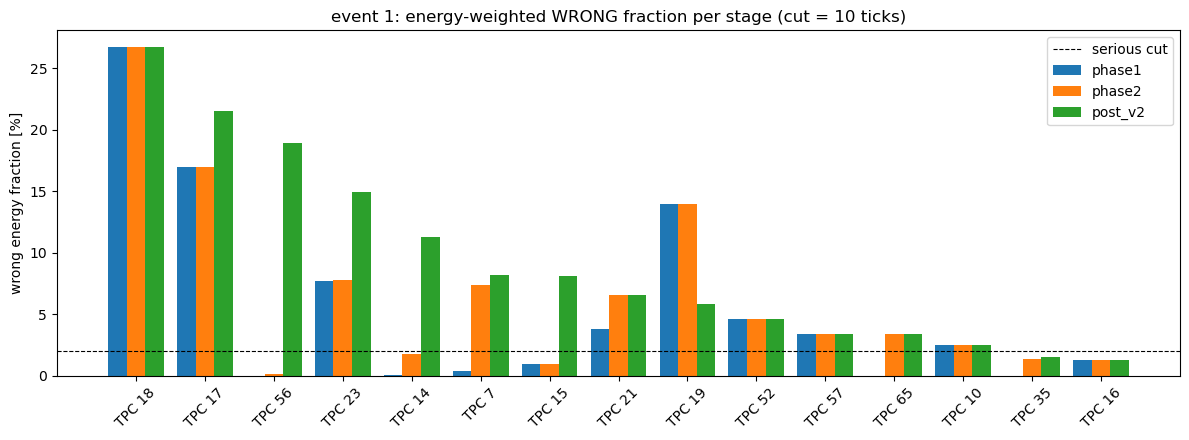

In [7]:
import matplotlib.pyplot as plt

_top = wrong_tpc_table[:15]
_x = np.arange(len(_top))
_w = 0.27
fig, ax = plt.subplots(figsize=(12, 4.5))
for _i, _nm in enumerate(_stage_names):
    ax.bar(_x + (_i - 1) * _w, [r[_nm + "_wrong"] * 100 for r in _top], _w, label=_nm)
ax.axhline(SERIOUS_WRONG_FRAC * 100, color="k", ls="--", lw=0.8, label="serious cut")
ax.set_xticks(_x)
ax.set_xticklabels([f"TPC {r['tpc']}" for r in _top], rotation=45)
ax.set_ylabel("wrong energy fraction [%]")
ax.set_title(f"event {ev_id}: energy-weighted WRONG fraction per stage (cut = {RESIDUAL_CUT_TICKS:.0f} ticks)")
ax.legend()
plt.tight_layout()
plt.show()

## Deep dive: scan one wrong TPC stage by stage

Set `WRONG_TPC_ID` (defaults to the worst one). The cells below give you, in order: the numeric per-stage story, the intersection-refinement moves and t0-candidate table for that TPC, a **per-cluster forensic table** (which cluster went to which t0 at which stage, vs truth), the 2D light/charge overlay, a 3D wrong-hits view, and truth-vs-reco clustered-t0 3D views. Re-run these cells with different `WRONG_TPC_ID` / `SCAN_STAGE` to scan.

In [8]:
WRONG_TPC_ID = wrong_tpc_ranking[0] if wrong_tpc_ranking else int(wrong_tpc_table[0]["tpc"])  # <-- change me
SCAN_STAGE = "post_v2"   # one of STAGE_SNAPSHOTS: "phase1" | "phase2" | "post_v2"

_row = next(r for r in wrong_tpc_table if r["tpc"] == WRONG_TPC_ID)
print(f"TPC {WRONG_TPC_ID} | truth-matched energy {_row['e_tot']:.1f} MeV | blame = {_row['blame']}")
for _nm in _stage_names:
    print(
        f"  {_nm:>9}: wrong {_row[_nm + '_wrong'] * 100:6.2f}% | "
        f"unassigned {_row[_nm + '_unassigned'] * 100:6.2f}%"
    )

# Intersection-refinement moves touching this TPC (if enabled).
if ir_stats:
    _recs = [p for p in ir_stats.get("pairs", []) if int(p.get("tpc", -1)) == WRONG_TPC_ID]
    if _recs:
        print(f"\nintersection-refinement moves in TPC {WRONG_TPC_ID}:")
        for p in _recs:
            print(f"  kind={p['kind']} labels={p['labels']} n_moved={p['n_moved']} E={p['energy_mev']} MeV")
    else:
        print(f"\nno intersection-refinement moves in TPC {WRONG_TPC_ID}")

# t0 candidate table + flash flags for this TPC.
_t0s = list(t0Candidates[WRONG_TPC_ID]) if WRONG_TPC_ID < len(t0Candidates) else []
_flags = ns["flash_cluster_received_by_tpc"][WRONG_TPC_ID] if WRONG_TPC_ID < len(ns["flash_cluster_received_by_tpc"]) else []
print(f"\nt0 candidates in TPC {WRONG_TPC_ID}: {_t0s}")
print(f"flash-received flags        : {[bool(v) for v in _flags]}")

# assignment_info entries for this TPC.
print(f"\nassignment_info entries for TPC {WRONG_TPC_ID}:")
for _k, _v in assignment_info.items():
    if isinstance(_k, tuple) and len(_k) == 2 and int(_k[1]) == WRONG_TPC_ID:
        _t0v = _v.get("t0", _v.get("assigned_t0", "?")) if isinstance(_v, dict) else _v
        _asn = _v.get("assigned", "?") if isinstance(_v, dict) else "?"
        print(f"  cluster {int(_k[0]):5d}: assigned={_asn} t0={_t0v}")

TPC 18 | truth-matched energy 376.4 MeV | blame = phase1
     phase1: wrong  26.76% | unassigned  34.63%
     phase2: wrong  26.76% | unassigned  34.63%
    post_v2: wrong  26.76% | unassigned  34.63%

no intersection-refinement moves in TPC 18

t0 candidates in TPC 18: [4.0, 64.0, 325.0, 341.0, 456.0, 482.0, 589.0, 618.0]
flash-received flags        : [False, False, False, True, False, False, False, True]

assignment_info entries for TPC 18:
  cluster    32: assigned=True t0=618.0
  cluster    48: assigned=True t0=341.0


In [9]:
# Per-cluster forensic table for WRONG_TPC_ID: which cluster sat at which t0 at each
# stage, vs its truth t0.  This is the "what happened at each stage" view.
_m_tpc = _tpc_arr == WRONG_TPC_ID
_lab_arr = np.asarray(ns["labels_global"])
_present = sorted(int(v) for v in np.unique(_lab_arr[_m_tpc]) if int(v) >= 0)


def _majority_t0(vals):
    v = vals[np.isfinite(vals) & (vals >= 0)]
    if v.size == 0:
        return None
    return float(np.median(v))


def _truth_med(idx):
    tt = truth_t0[idx]
    ww = _E_arr[idx]
    ok = np.isfinite(tt)
    if not ok.any():
        return None
    order = np.argsort(tt[ok])
    cw = np.cumsum(ww[ok][order])
    return float(tt[ok][order][np.searchsorted(cw, 0.5 * cw[-1])])


_rows = []
for _L in _present:
    _idx = np.flatnonzero(_m_tpc & (_lab_arr == _L))
    _e = float(_E_arr[_idx].sum())
    _tt = _truth_med(_idx)
    _entry = {
        "label": _L,
        "type": str(label_info.get(_L, {}).get("type", "?")),
        "n": int(_idx.size),
        "E": _e,
        "truth": _tt,
    }
    for _nm in _stage_names:
        _entry[_nm] = _majority_t0(np.asarray(STAGE_SNAPSHOTS[_nm], dtype=np.float64)[_idx])
    _rows.append(_entry)

_rows.sort(key=lambda r: -r["E"])


def _fmt_t0(v, truth):
    if v is None:
        return "     --  "
    mark = " "
    if truth is not None:
        mark = "*" if abs(v - truth) > RESIDUAL_CUT_TICKS else " "
    return f"{v:8.1f}{mark}"


print(f"clusters in TPC {WRONG_TPC_ID} ('*' = majority t0 differs from truth by > {RESIDUAL_CUT_TICKS:.0f} ticks)")
print(f"{'label':>6} {'type':>8} {'nhits':>6} {'E[MeV]':>8} {'truth_t0':>9} | " + " | ".join(f"{_nm:>9}" for _nm in _stage_names))
for r in _rows[:40]:
    tt = f"{r['truth']:9.1f}" if r["truth"] is not None else "      -- "
    cols = " | ".join(_fmt_t0(r[_nm], r["truth"]) for _nm in _stage_names)
    print(f"{r['label']:>6} {r['type']:>8} {r['n']:>6} {r['E']:>8.2f} {tt} | {cols}")

clusters in TPC 18 ('*' = majority t0 differs from truth by > 10 ticks)
 label     type  nhits   E[MeV]  truth_t0 |    phase1 |    phase2 |   post_v2
    32    track    538   145.29     618.1 |    618.0  |    618.0  |    618.0 
    48    track    271   100.72     481.0 |    341.0* |    341.0* |    341.0*
   520  cluster    119    40.96     588.4 |      --   |      --   |      --  
   508  cluster     85    32.62     609.8 |      --   |      --   |      --  
   513  cluster     31    17.05     341.0 |      --   |      --   |      --  
   512  cluster     13     4.68     341.0 |      --   |      --   |      --  
   510  cluster     14     4.34     588.5 |      --   |      --   |      --  
   509  cluster     12     3.92      62.1 |      --   |      --   |      --  
   514  cluster      9     3.12     618.1 |      --   |      --   |      --  
   522  cluster     11     3.10     588.3 |      --   |      --   |      --  
   518  cluster      6     3.02     588.4 |      --   |      --   |   

Plotting 2D comparison for TPC 18 at stage 'post_v2' ...
Total energy in TPC 18: 376.36


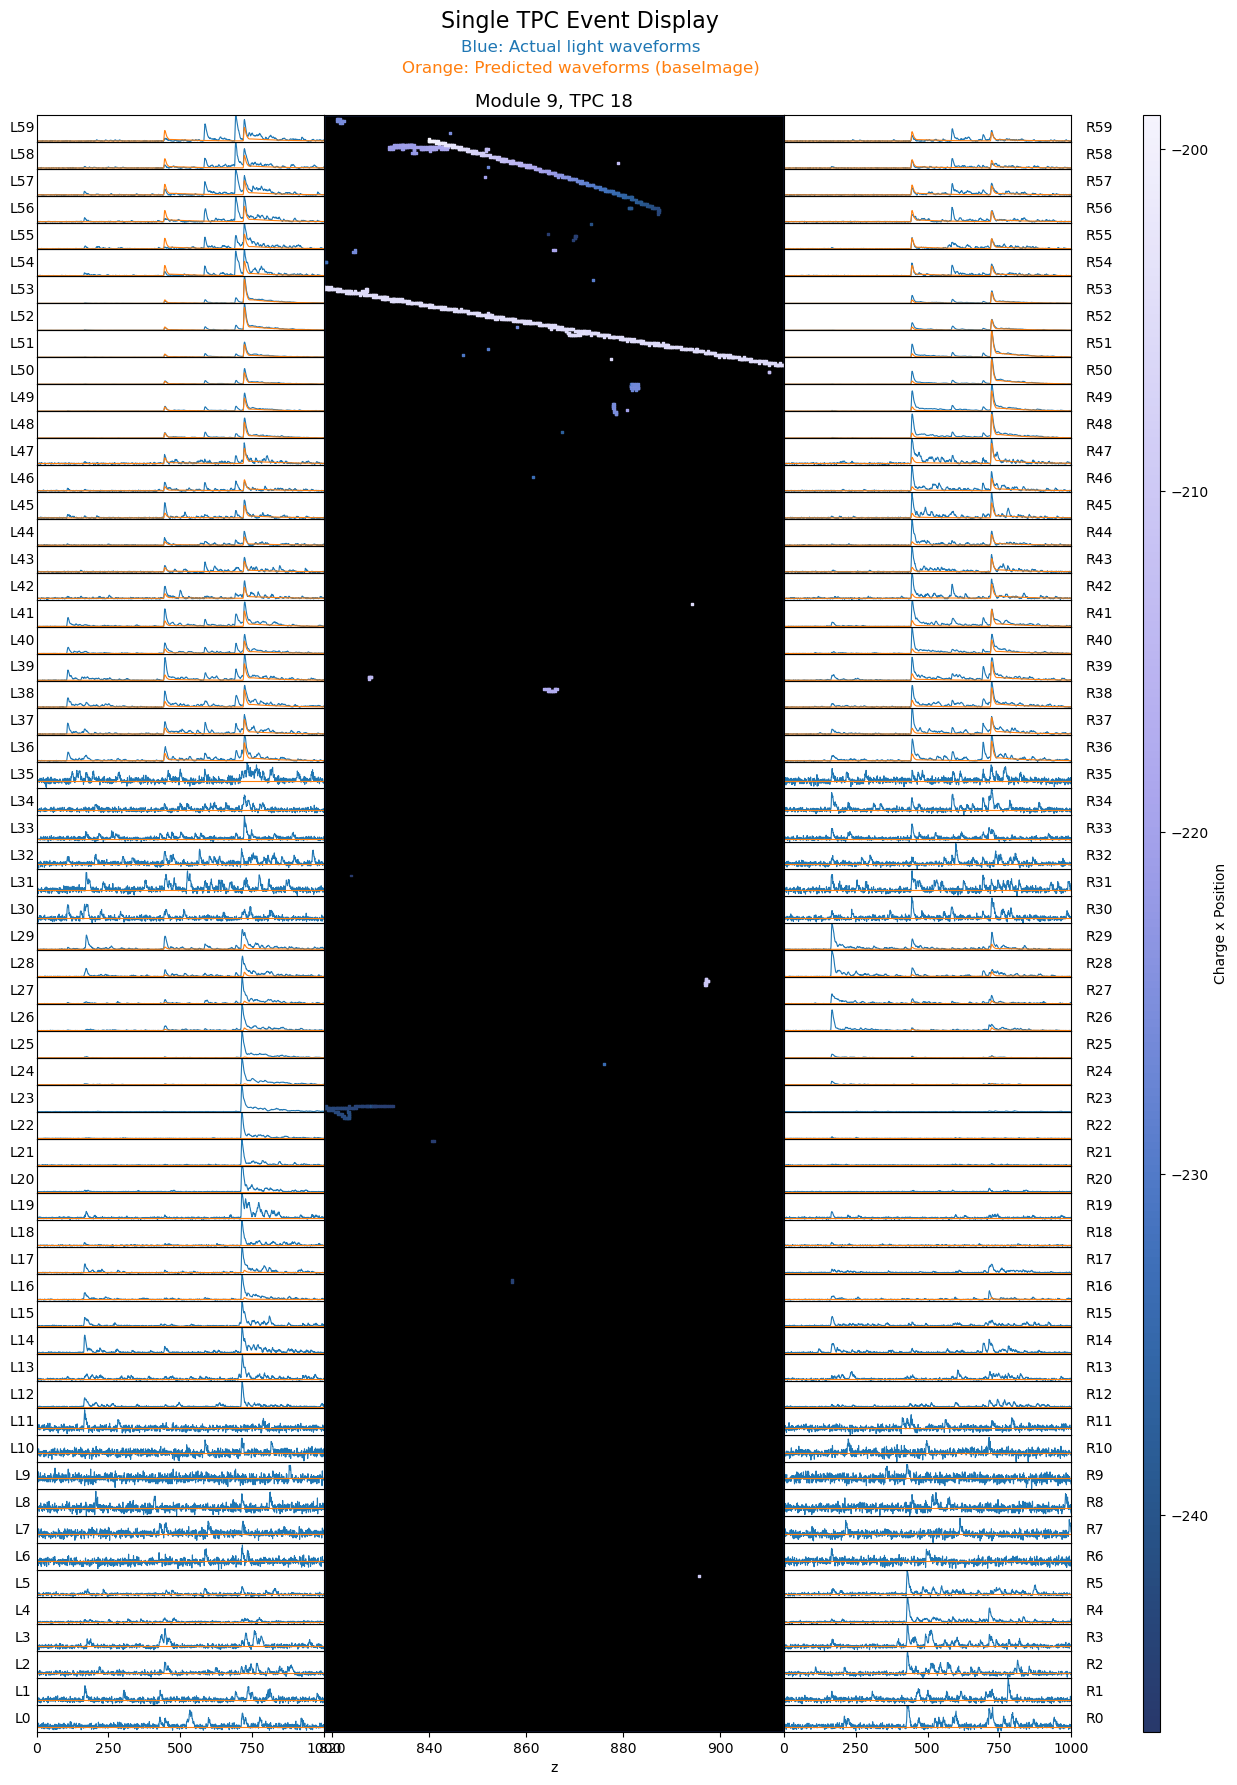

baseImage delta    phase2 vs previous: max|d|=0.0 sum|d|=0.0 nonzero-ticks=0
baseImage delta   post_v2 vs previous: max|d|=0.0 sum|d|=0.0 nonzero-ticks=0


In [10]:
from visualizationTools import plot_tpc_light_and_charge, plot_tpc_3d_charge
import visualizationTools
importlib.reload(visualizationTools)
from visualizationTools import plot_tpc_light_and_charge, plot_tpc_3d_charge

# 2D actual-vs-predicted light + charge for the chosen TPC at the chosen stage.
print(f"Plotting 2D comparison for TPC {WRONG_TPC_ID} at stage '{SCAN_STAGE}' ...")
actual_wvfm = fullLightWaveform[WRONG_TPC_ID]
pred_wvfm = STAGE_BASEIMAGES[SCAN_STAGE][WRONG_TPC_ID]

plot_tpc_light_and_charge(
    ev_id=ev_id,
    TPCid=WRONG_TPC_ID,
    hits_full_ev=hits_evt,
    actual=actual_wvfm,
    predicted=pred_wvfm,
    geom_map=geom_map,
    individualScaling=False,
)

# How much the predicted image changed at each stage (like the vRelease5 before/after cell).
_prev = None
for _nm in _stage_names:
    _img = STAGE_BASEIMAGES[_nm][WRONG_TPC_ID]
    if _prev is not None:
        _d = _img - _prev
        print(
            f"baseImage delta {_nm:>9} vs previous: max|d|={float(np.max(np.abs(_d))):.1f} "
            f"sum|d|={float(np.sum(np.abs(_d))):.1f} nonzero-ticks={int(np.count_nonzero(np.abs(_d) > 1e-3))}"
        )
    _prev = _img

Saved html: wrong_hits_TPC18_post_v2.html


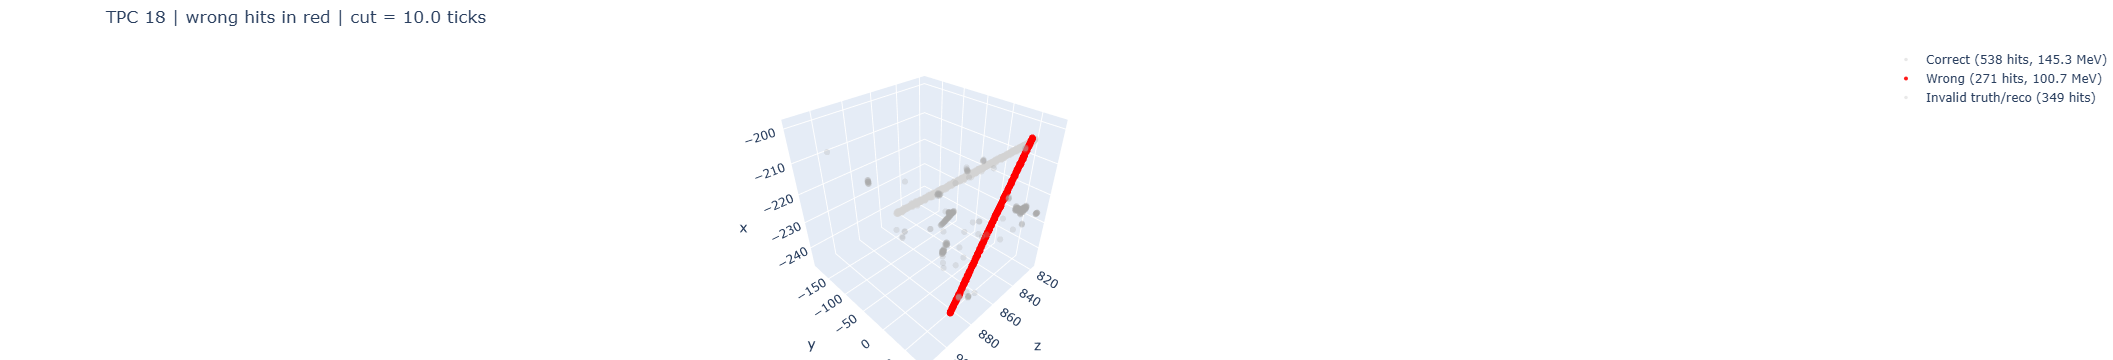

TPC 18
Residual cut                 : 10.00 ticks (160 ns)
Finite truth+reco hits       : 809
Wrong hits                   : 271
Correct energy               : 145.2872 MeV
Wrong energy                 : 100.7220 MeV
Correct energy fraction      : 59.06%
Wrong energy fraction        : 40.94%
Saved: wrong_hits_TPC18_post_v2.html
Wrong hits: 271
Wrong energy: 100.7220 MeV
Wrong energy fraction: 40.94%


In [11]:
# 3D wrong-hits view for the chosen stage (red = |reco - truth| > cut, gray = correct).
_ns_for_plot = dict(globals())
_ns_for_plot["hit_timestamps"] = np.asarray(STAGE_SNAPSHOTS[SCAN_STAGE], dtype=np.float64)

SAVE_HTML = f"wrong_hits_TPC{WRONG_TPC_ID}_{SCAN_STAGE}.html"
wrong_hits_plot = tp.plot_wrong_hits_from_namespace(
    _ns_for_plot,
    TPCid=WRONG_TPC_ID,
    truth_t0=truth_t0,
    residual_cut_ticks=RESIDUAL_CUT_TICKS,
    save_path=SAVE_HTML,
    marker_size=3.5,
    correct_color="lightgray",
    wrong_color="red",
    show=True,
)
print(f"Saved: {SAVE_HTML}")
print(f"Wrong hits: {wrong_hits_plot['n_wrong_hits']}")
print(f"Wrong energy: {wrong_hits_plot['wrong_energy']:.4f} MeV")
print(f"Wrong energy fraction: {wrong_hits_plot['wrong_energy_fraction']:.2f}%")

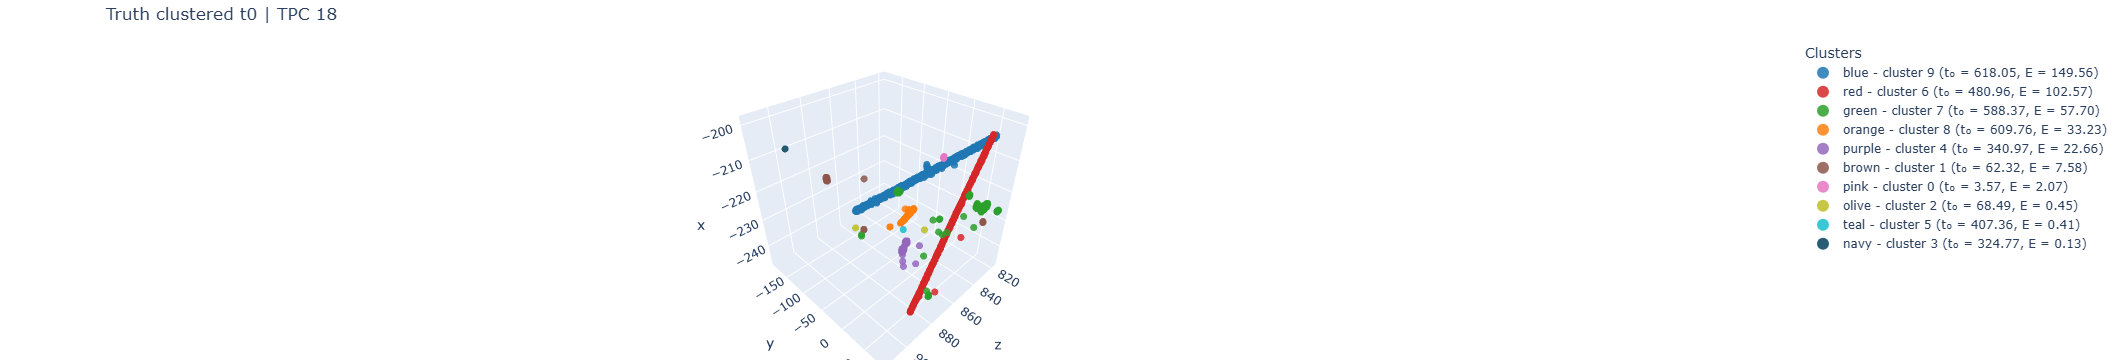

Saved truth clustered-t0 plot: truth_clustered_t0_TPC18.html


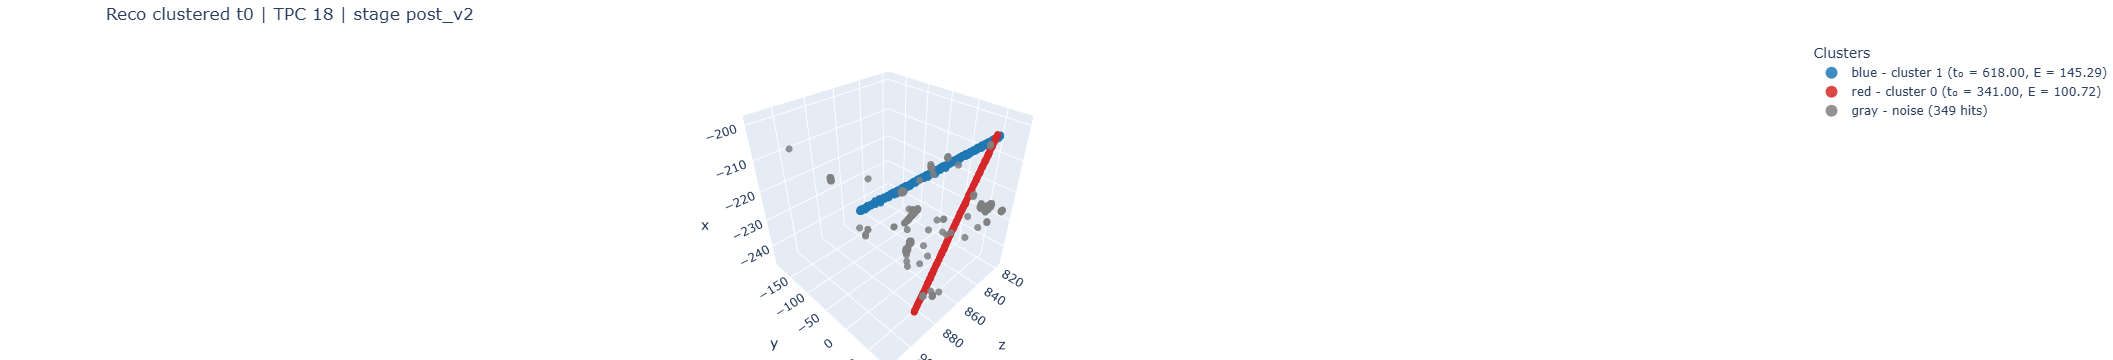

Saved reco clustered-t0 plot: reco_clustered_t0_TPC18_post_v2.html


In [12]:
from M5p1 import plottingTools as pt
importlib.reload(pt)

# Truth vs reco clustered-t0 3D plots (mirror of the vRelease5 cell).
T0_GROUP_WINDOW_TICKS = 5
TRUTH_SAVE_HTML = f"truth_clustered_t0_TPC{WRONG_TPC_ID}.html"
RECO_SAVE_HTML = f"reco_clustered_t0_TPC{WRONG_TPC_ID}_{SCAN_STAGE}.html"

truth_t0_plot = tp.plot_truth_from_namespace(
    globals(),
    target_tpc=WRONG_TPC_ID,
    mode="t0",
    time_window=T0_GROUP_WINDOW_TICKS,
    convert_t0_to_matching_ticks=True,
    title=f"Truth clustered t0 | TPC {WRONG_TPC_ID}",
    save_path=TRUTH_SAVE_HTML,
    show=True,
)
print(f"Saved truth clustered-t0 plot: {TRUTH_SAVE_HTML}")

_tpc_mask = _tpc_arr == int(WRONG_TPC_ID)
_reco_t0 = np.asarray(STAGE_SNAPSHOTS[SCAN_STAGE], dtype=np.float64)
_reco_t0_safe = np.where(np.isfinite(_reco_t0), _reco_t0, -1.0)
_reco_labels_tpc = pt.group_hits_by_time(_reco_t0_safe[_tpc_mask], time_window=T0_GROUP_WINDOW_TICKS)

pt.plot_3d_clusters_with_t0(
    x=np.asarray(xset)[_tpc_mask],
    y=np.asarray(yset)[_tpc_mask],
    z=np.asarray(zset)[_tpc_mask],
    labels=_reco_labels_tpc,
    t0s=_reco_t0_safe[_tpc_mask],
    energies=np.asarray(Eset, dtype=np.float64)[_tpc_mask],
    title=f"Reco clustered t0 | TPC {WRONG_TPC_ID} | stage {SCAN_STAGE}",
    save_path=RECO_SAVE_HTML,
)
print(f"Saved reco clustered-t0 plot: {RECO_SAVE_HTML}")

## Event-level truth residual histogram (backbone-only final = post V2)

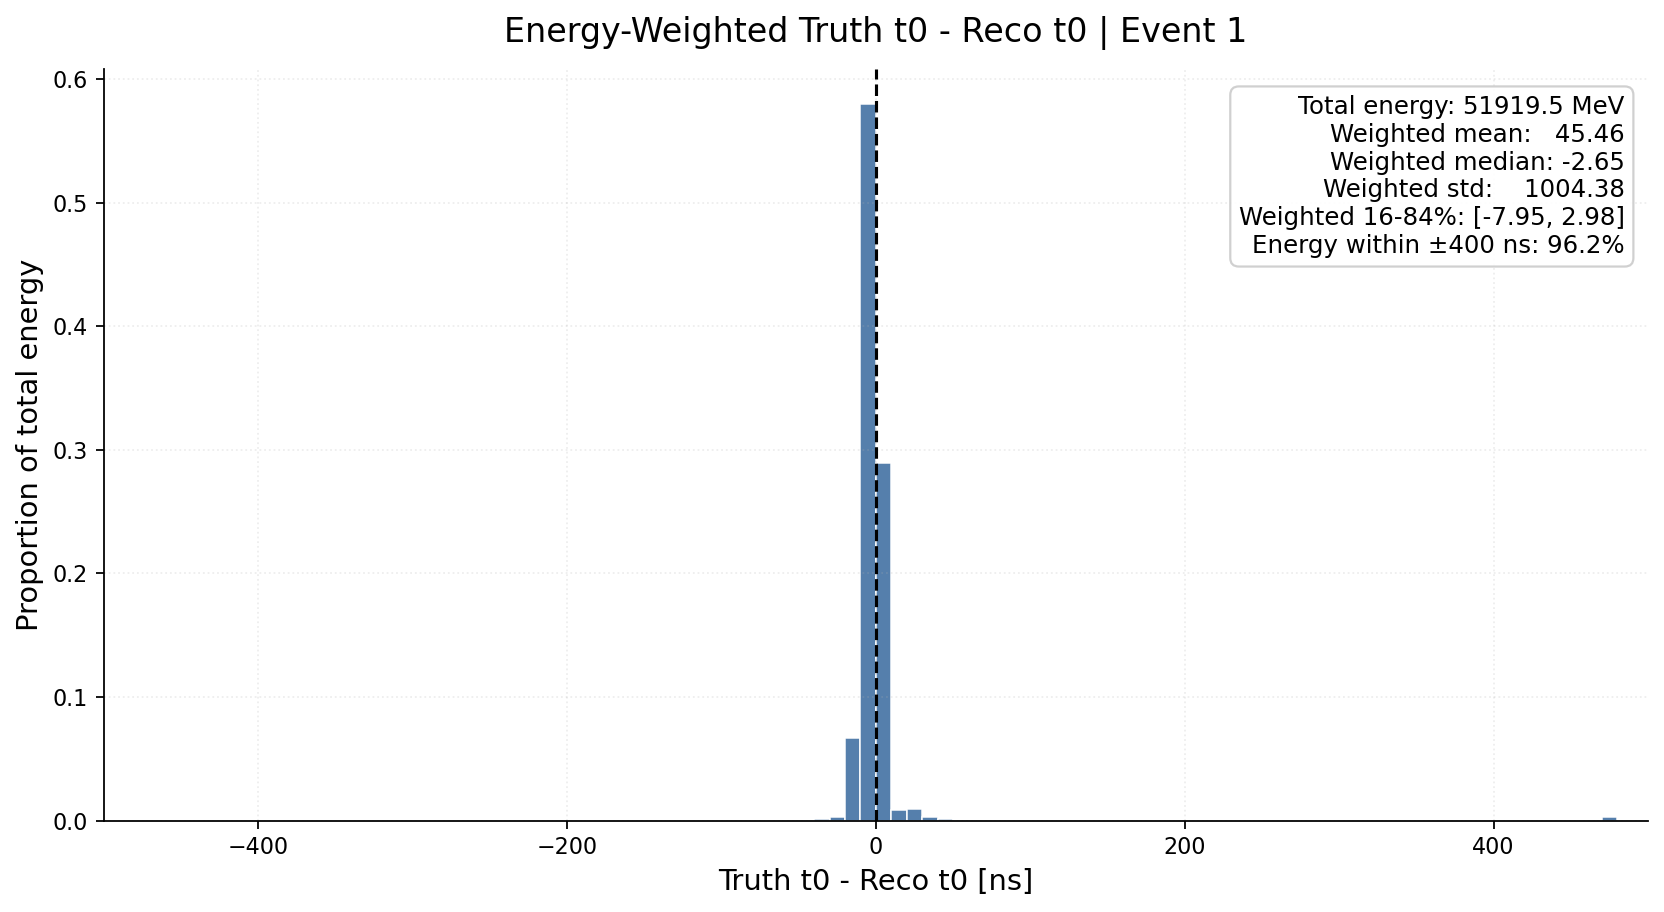

Finite weighted hits : 153579
Total energy         : 51919.5460 MeV
Weighted mean        : 45.4612
Weighted median      : -2.6533
Weighted std         : 1004.3767
Weighted 16-84%      : [-7.9507, 2.9757]
Energy within ±400 ns : 96.2%
Energy within +/- 400 ns : 49926.0074 MeV
Total weighted energy        : 51919.5460 MeV
Fraction within +/- 400 ns : 96.16%


In [13]:
final_t0_residual_histogram = tp.plot_event_energy_weighted_t0_residual_from_hdf5(
    h5,
    hits_ref,
    event_id=ev_id,
    hits_full=hits_full,
    reco_t0=hit_timestamps,
    convert_to_matching_ticks=True,
    use_ns=True,
    ns_per_tick=NS_PER_TICK,
    window_limit=400.0,
    save_path=f"backbone_residual_ev{ev_id}.png",
    show=True,
    print_summary=True,
)

## Notes

- **Backbone-only semantics**: Phase 3 (small-cluster error-matrix association) is *not* run, so every single-TPC blob ≤ 50 MeV stays unassigned by design. When ranking problems, read the **wrong%** columns, not unassigned%.
- **Typical scan flow**: run all cells → look at the ranking table / bar chart → set `WRONG_TPC_ID` and `SCAN_STAGE` → the per-cluster forensic table usually identifies the culprit cluster and the stage where its majority t0 went wrong → use the 2D overlay + 3D views to understand why (missing flash candidate? wrong scan minimum? V2 move? refinement move?).
- **Intersection refinement**: toggle `REFINE_INTERSECTIONS` in the setup cell and re-run to A/B its effect; its per-TPC moves are printed in the deep-dive cell.
- Stage snapshots (`hit_ts_phase1/phase2/post_v2`, `STAGE_BASEIMAGES`) are plain arrays — feel free to add cells diffing them in other ways.

track label 48: 392 hits, 143.2 MeV
  TPCs with hits          : [18, 19]
  TPCs with light images  : [18, 19]
  TPC  nhits   E[MeV]  reco_t0  truth_t0
   18    271   100.72    341.0     481.0
   19    121    42.46    480.0     480.9

current t0 = 341.0 | truth t0 = 480.9

scan inputs: 33 support channels stacked over TPCs [18, 19] (per-TPC: [24, 9])


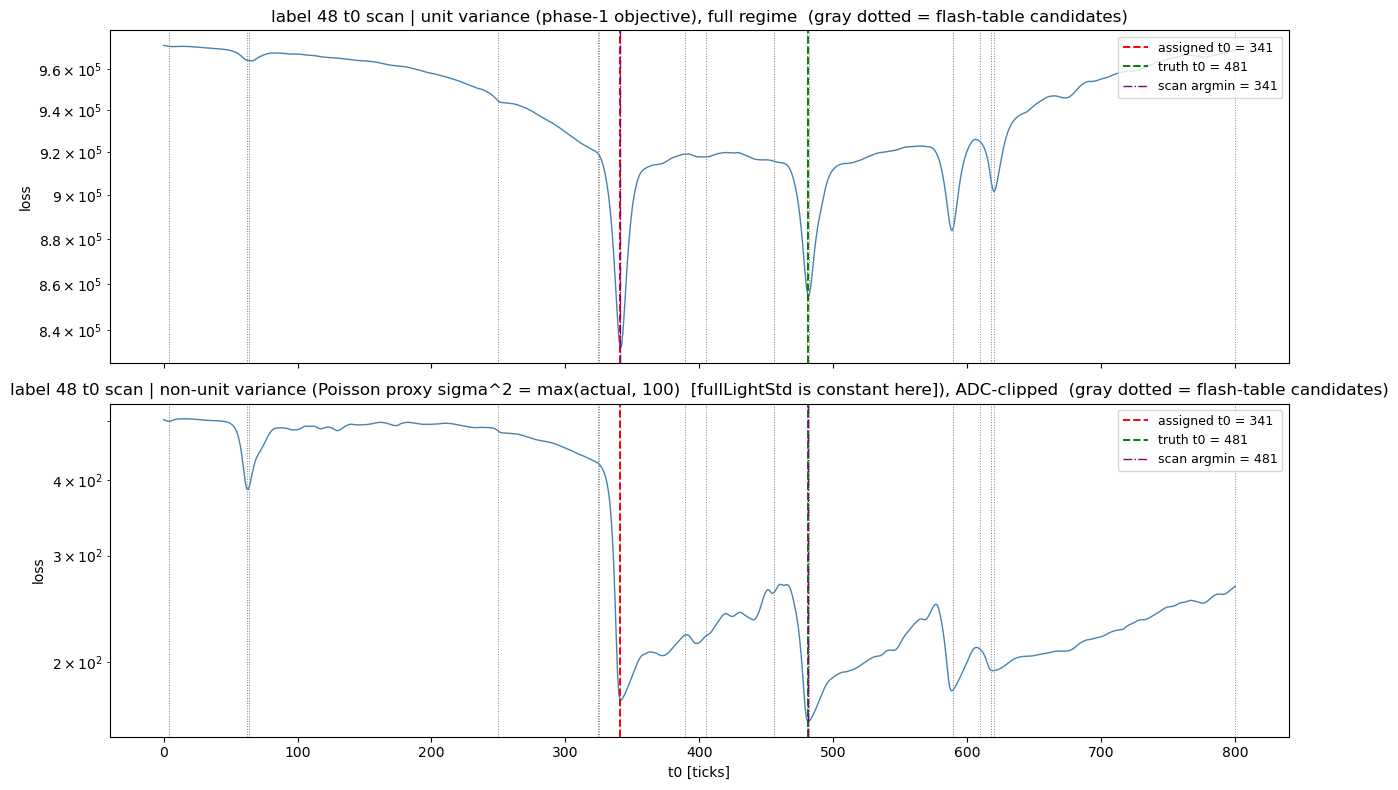

     unit: argmin=341 loss(assigned 341)=8.322e+05 loss(truth 481)=8.55e+05 ratio=0.973
 non-unit: argmin=481 loss(assigned 341)=173 loss(truth 481)=159.6 ratio=1.084

--- TPC 19 (track 48 passes through) ---
Total energy in TPC 19: 2776.17


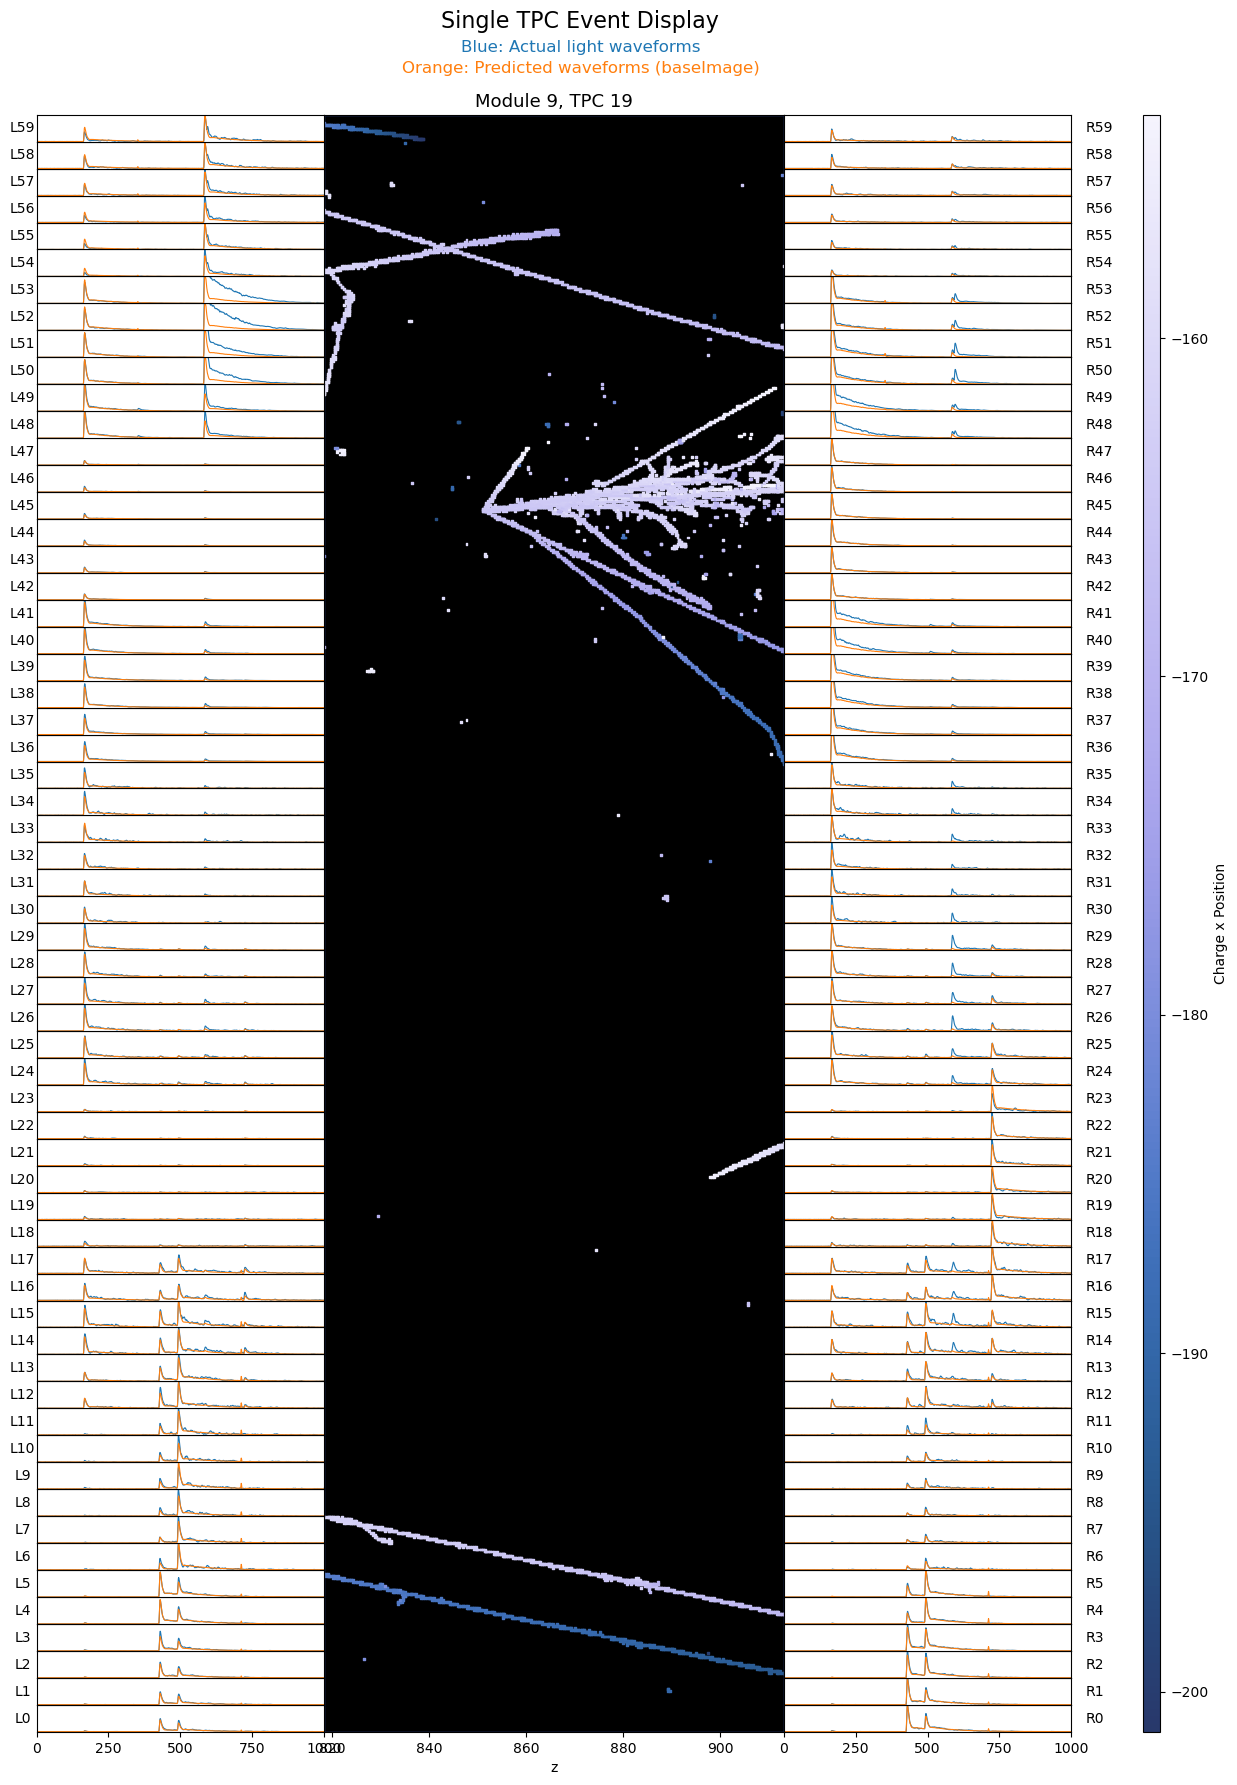

In [14]:
# =====================================================================
# Misplaced-track diagnostics: TPC span + full-regime t0 loss scans
# =====================================================================
from v10_3_support import stack_cluster_fit_inputs_v10_3
from M5p1.first_stage_matching.track_stage import (
    correlation_unit_likelihood_curve_with_base,
    exact_likelihood_curve_with_base,
    fast_stack_images,
)
from pulse_shapes import timeinterpolation
import matplotlib.pyplot as plt

TRACK_LABEL = 48            # <-- the misplaced track (from the forensic table)
SCAN_SEARCH_RANGE = 800     # every integer tick in [0, 800] -- NOT just the flash table
PULSE_PEAK_TICK = 105       # template peak offset (refine_t0_from_local_peak convention)

_lab_arr = np.asarray(ns["labels_global"])
_members = np.flatnonzero(_lab_arr == TRACK_LABEL)
assert _members.size > 0, f"label {TRACK_LABEL} has no hits"

# ---------- 1. every TPC this track spans ----------
_hit_tpcs = sorted(int(v) for v in np.unique(_tpc_arr[_members]))
_img_tpcs = sorted(int(t) for t in cluster_to_tpcs.get(TRACK_LABEL, []))
print(f"track label {TRACK_LABEL}: {_members.size} hits, {float(_E_arr[_members].sum()):.1f} MeV")
print(f"  TPCs with hits          : {_hit_tpcs}")
print(f"  TPCs with light images  : {_img_tpcs}")
print(f"{'TPC':>5} {'nhits':>6} {'E[MeV]':>8} {'reco_t0':>8} {'truth_t0':>9}")
for _t in _hit_tpcs:
    _mi = _members[_tpc_arr[_members] == _t]
    _r = np.asarray(hit_timestamps, dtype=np.float64)[_mi]
    _r = _r[np.isfinite(_r) & (_r >= 0)]
    _tt = truth_t0[_mi]
    _tt = _tt[np.isfinite(_tt)]
    print(f"{_t:>5} {_mi.size:>6} {float(_E_arr[_mi].sum()):>8.2f} "
          f"{np.median(_r) if _r.size else float('nan'):>8.1f} "
          f"{np.median(_tt) if _tt.size else float('nan'):>9.1f}")

_r_all = np.asarray(hit_timestamps, dtype=np.float64)[_members]
_r_all = _r_all[np.isfinite(_r_all) & (_r_all >= 0)]
track_cur_t0 = float(np.median(_r_all)) if _r_all.size else float("nan")
_tt_all = truth_t0[_members]
_tt_all = _tt_all[np.isfinite(_tt_all)]
track_truth_t0 = float(np.median(_tt_all)) if _tt_all.size else float("nan")
print(f"\ncurrent t0 = {track_cur_t0:.1f} | truth t0 = {track_truth_t0:.1f}")

# ---------- rebuild the scan inputs with the track REMOVED from the base ----------
_scan_tpcs = np.sort(np.asarray(
    [t for t in _img_tpcs if t < fullLightWaveform.shape[0]], dtype=np.int32))
_full_image = fast_stack_images(imageMaps, TRACK_LABEL, _scan_tpcs)
_shifted_cur = timeinterpolation(_full_image, shift=float(track_cur_t0), baseline=0).astype(np.float32)
base_minus_track = np.asarray(baseImage, dtype=np.float32).copy()
base_minus_track[_scan_tpcs] -= _shifted_cur.reshape(_scan_tpcs.size, 120, -1)
np.clip(base_minus_track, 0.0, None, out=base_minus_track)  # guard tiny negatives if V2 re-predicted this family

fit_image, fit_base, fit_actual, fit_var, fit_meta = stack_cluster_fit_inputs_v10_3(
    clusterid=int(TRACK_LABEL),
    tpcids=_scan_tpcs,
    image_maps=imageMaps,
    base_image=base_minus_track,
    full_light_waveform=fullLightWaveform,
    full_light_std=ns["fullLightStd"],
    channel_support_cache=ns["cluster_channel_support_cache"],
    use_support_mask=True,              # same masking the phase-1 track placement used
    saturated_channel_cache=ns["saturated_channel_cache"],
)
print(f"\nscan inputs: {fit_image.shape[0]} support channels stacked over TPCs "
      f"{[m['tpcid'] for m in fit_meta]} (per-TPC: {[m['n_fit_channels'] for m in fit_meta]})")

# ---------- 2. unit-variance loss over the entire regime ----------
shifts_u, loss_u = correlation_unit_likelihood_curve_with_base(
    fit_image, fit_base, fit_actual, search_range=SCAN_SEARCH_RANGE, engine="fft")

# ---------- 3. non-unit-variance loss over the entire regime ----------
_var_trivial = bool(np.allclose(fit_var, fit_var.flat[0]))
if _var_trivial:
    # no variance model in this install -> fullLightStd is constant; use a
    # Poisson-style proxy sigma^2 = max(actual, floor) so the plot is informative
    fit_var_used = np.maximum(fit_actual.astype(np.float32), 100.0)
    _var_label = "Poisson proxy sigma^2 = max(actual, 100)  [fullLightStd is constant here]"
else:
    fit_var_used = fit_var
    _var_label = "variance-model fullLightStd"
shifts_e, loss_e = exact_likelihood_curve_with_base(
    fit_image, fit_base, fit_actual, fit_var_used,
    search_range=SCAN_SEARCH_RANGE, adc_clip=ADC_CLIP)

_cand_union = sorted({float(v) for _t in _scan_tpcs for v in t0Candidates[int(_t)]})
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for _ax, _sh, _ls, _ttl in (
    (axes[0], shifts_u, loss_u, "unit variance (phase-1 objective), full regime"),
    (axes[1], shifts_e, loss_e, f"non-unit variance ({_var_label}), ADC-clipped"),
):
    _ax.plot(_sh, _ls, lw=1.0, color="steelblue")
    for _c in _cand_union:
        _ax.axvline(_c, color="gray", ls=":", lw=0.7)
    _ax.axvline(track_cur_t0, color="red", ls="--", lw=1.4,
                label=f"assigned t0 = {track_cur_t0:.0f}")
    _ax.axvline(track_truth_t0, color="green", ls="--", lw=1.4,
                label=f"truth t0 = {track_truth_t0:.0f}")
    _amin = int(_sh[int(np.argmin(_ls))])
    _ax.axvline(_amin, color="purple", ls="-.", lw=1.0, label=f"scan argmin = {_amin}")
    _ax.set_yscale("log")
    _ax.set_ylabel("loss")
    _ax.set_title(f"label {TRACK_LABEL} t0 scan | {_ttl}  (gray dotted = flash-table candidates)")
    _ax.legend(loc="upper right", fontsize=9)
axes[1].set_xlabel("t0 [ticks]")
plt.tight_layout()
plt.show()

for _nm, _sh, _ls in (("unit", shifts_u, loss_u), ("non-unit", shifts_e, loss_e)):
    _i_cur = int(np.argmin(np.abs(_sh - track_cur_t0)))
    _i_tru = int(np.argmin(np.abs(_sh - track_truth_t0)))
    print(f"{_nm:>9}: argmin={int(_sh[int(np.argmin(_ls))])} "
          f"loss(assigned {track_cur_t0:.0f})={float(_ls[_i_cur]):.4g} "
          f"loss(truth {track_truth_t0:.0f})={float(_ls[_i_tru]):.4g} "
          f"ratio={float(_ls[_i_cur]) / max(float(_ls[_i_tru]), 1e-12):.3f}")

# ---------- 4. light/charge overlay for every OTHER TPC the track crosses ----------
from visualizationTools import plot_tpc_light_and_charge
for _t in _hit_tpcs:
    if int(_t) == int(WRONG_TPC_ID):
        continue
    if int(_t) >= fullLightWaveform.shape[0]:
        continue
    print(f"\n--- TPC {_t} (track {TRACK_LABEL} passes through) ---")
    plot_tpc_light_and_charge(
        ev_id=ev_id,
        TPCid=int(_t),
        hits_full_ev=hits_evt,
        actual=fullLightWaveform[int(_t)],
        predicted=baseImage[int(_t)],
        geom_map=geom_map,
        individualScaling=False,
    )


support channels of cluster 48 in TPC 18 (multi_tpc_track): [48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119]


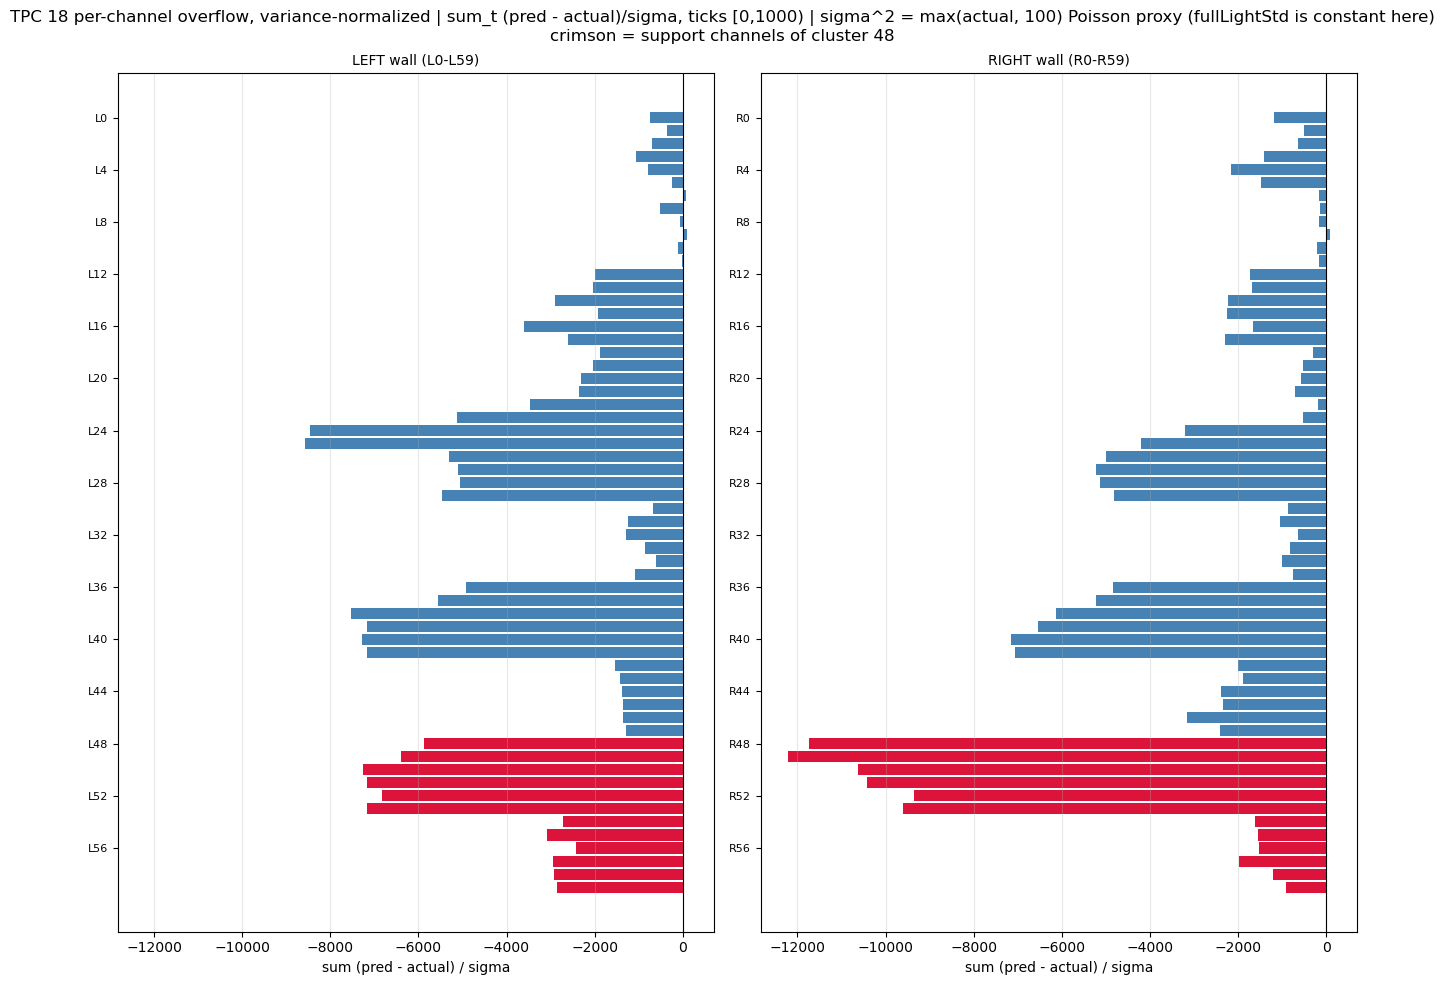

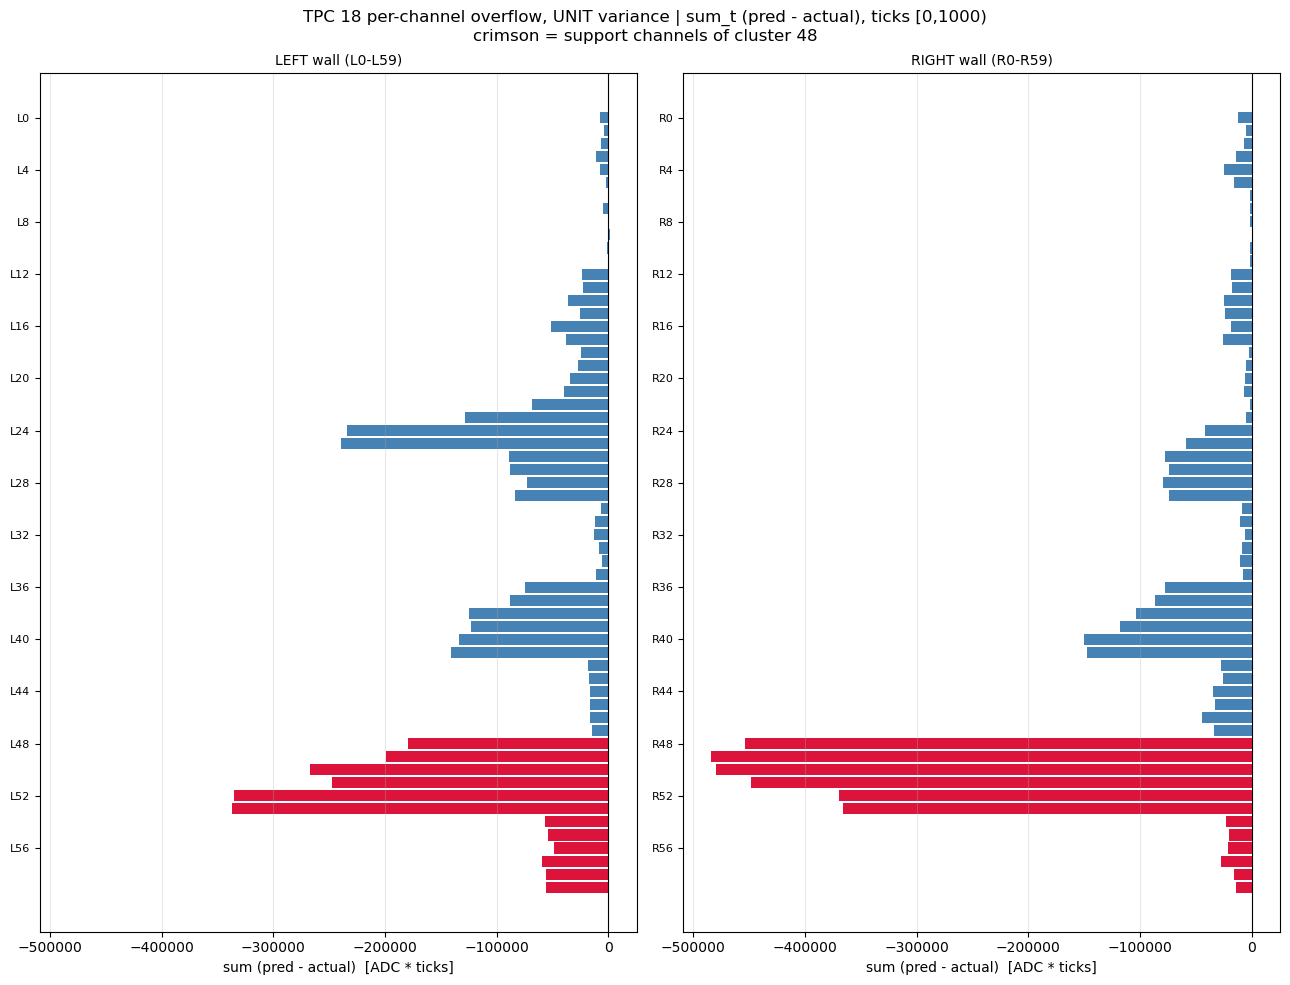


top-12 overflow channels (variance-normalized):
  ch   9 (  L9)         sum(pred-actual)/sigma =       96.5 | raw =          965
  ch  69 (  R9)         sum(pred-actual)/sigma =       90.9 | raw =          909
  ch   6 (  L6)         sum(pred-actual)/sigma =       81.1 | raw =          811
  ch  11 ( L11)         sum(pred-actual)/sigma =      -24.2 | raw =         -252
  ch   8 (  L8)         sum(pred-actual)/sigma =      -68.9 | raw =         -689
  ch  10 ( L10)         sum(pred-actual)/sigma =     -109.3 | raw =        -1093
  ch  67 (  R7)         sum(pred-actual)/sigma =     -141.6 | raw =        -1416
  ch  71 ( R11)         sum(pred-actual)/sigma =     -159.1 | raw =        -1591
  ch  66 (  R6)         sum(pred-actual)/sigma =     -162.5 | raw =        -1625
  ch  68 (  R8)         sum(pred-actual)/sigma =     -165.5 | raw =        -1655
  ch  82 ( R22)         sum(pred-actual)/sigma =     -193.5 | raw =        -2063
  ch  70 ( R10)         sum(pred-actual)/sigma =     -204.3 

In [15]:
# =====================================================================
# Per-channel overflow extent for one TPC (design input for a
# "pause placement on overflow" check).  Channels 0-59 = LEFT wall (L#),
# 60-119 = RIGHT wall (R#).  Bars run top-to-bottom in channel order.
# Support channels of OV_LABEL are colored crimson.
# =====================================================================
import matplotlib.pyplot as plt

OV_TPC = int(WRONG_TPC_ID)      # TPC to inspect (18)
OV_LABEL = 48                   # cluster whose support channels to highlight (None = no highlight)
TICK_LO, TICK_HI = 0, WVFM_LEN  # overflow integration window; e.g. around the misplaced pulse:
                                # TICK_LO, TICK_HI = 341+105-50, 341+105+250

_ov_actual = np.asarray(fullLightWaveform, dtype=np.float64)[OV_TPC, :, TICK_LO:TICK_HI]
_ov_pred = np.asarray(baseImage, dtype=np.float64)[OV_TPC, :, TICK_LO:TICK_HI]
_ov_var = np.asarray(ns["fullLightStd"], dtype=np.float64)[OV_TPC, :, TICK_LO:TICK_HI]
if bool(np.allclose(_ov_var, _ov_var.flat[0])):
    _ov_var = np.maximum(_ov_actual, 100.0)
    _ov_var_label = "sigma^2 = max(actual, 100) Poisson proxy (fullLightStd is constant here)"
else:
    _ov_var_label = "variance-model fullLightStd"

_resid = _ov_pred - _ov_actual                       # >0 = predicted MORE light than seen (overflow)
ov_per_channel_sigma = (_resid / np.sqrt(_ov_var)).sum(axis=1)   # variance-normalized, signed
ov_per_channel_raw = _resid.sum(axis=1)                          # unit variance (plain ADC*ticks)

# support channels of the chosen cluster in this TPC
_supp = np.zeros(120, dtype=bool)
if OV_LABEL is not None:
    _entry = ns["cluster_channel_support_cache"].get((int(OV_LABEL), OV_TPC))
    if _entry is not None:
        _supp[np.asarray(_entry["channel_indices"], dtype=int)] = True
        print(f"support channels of cluster {OV_LABEL} in TPC {OV_TPC} "
              f"({_entry['support_mode']}): {sorted(np.flatnonzero(_supp).tolist())}")
    else:
        print(f"NOTE: no support-cache entry for ({OV_LABEL}, {OV_TPC})")


def _overflow_bars(values, title, xlabel):
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 10), sharex=True)
    for ax, lo, side in ((axL, 0, "LEFT wall (L0-L59)"), (axR, 60, "RIGHT wall (R0-R59)")):
        ch = np.arange(lo, lo + 60)
        colors = ["crimson" if _supp[c] else "steelblue" for c in ch]
        ax.barh(np.arange(60), values[ch], color=colors, height=0.85)
        ax.set_yticks(np.arange(0, 60, 4))
        ax.set_yticklabels([f"{'L' if lo == 0 else 'R'}{i}" for i in range(0, 60, 4)], fontsize=8)
        ax.invert_yaxis()                        # channel 0 at the TOP
        ax.axvline(0.0, color="k", lw=0.8)
        ax.set_title(side, fontsize=10)
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", alpha=0.3)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


_overflow_bars(
    ov_per_channel_sigma,
    f"TPC {OV_TPC} per-channel overflow, variance-normalized | sum_t (pred - actual)/sigma, "
    f"ticks [{TICK_LO},{TICK_HI}) | {_ov_var_label}\n"
    f"crimson = support channels of cluster {OV_LABEL}",
    "sum (pred - actual) / sigma",
)
_overflow_bars(
    ov_per_channel_raw,
    f"TPC {OV_TPC} per-channel overflow, UNIT variance | sum_t (pred - actual), "
    f"ticks [{TICK_LO},{TICK_HI})\ncrimson = support channels of cluster {OV_LABEL}",
    "sum (pred - actual)  [ADC * ticks]",
)

# ---------- numbers for designing the pause-on-overflow check ----------
def _side_label(c):
    return f"L{c}" if c < 60 else f"R{c - 60}"

_order = np.argsort(ov_per_channel_sigma)[::-1]
print(f"\ntop-12 overflow channels (variance-normalized):")
for c in _order[:12]:
    print(f"  ch {int(c):3d} ({_side_label(int(c)):>4}) "
          f"{'SUPPORT' if _supp[int(c)] else '       '} "
          f"sum(pred-actual)/sigma = {ov_per_channel_sigma[int(c)]:>10.1f} | "
          f"raw = {ov_per_channel_raw[int(c)]:>12.0f}")

_pos = np.clip(ov_per_channel_sigma, 0, None)
print(f"\noverflow summary (positive side only):")
print(f"  support channels    : n={int(_supp.sum())} "
      f"sum={float(_pos[_supp].sum()):.1f} max={float(_pos[_supp].max()) if _supp.any() else 0.0:.1f}")
print(f"  non-support channels: n={int((~_supp).sum())} "
      f"sum={float(_pos[~_supp].sum()):.1f} max={float(_pos[~_supp].max()):.1f}")


support channels of cluster 48 in TPC 18 (multi_tpc_track): [48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119]


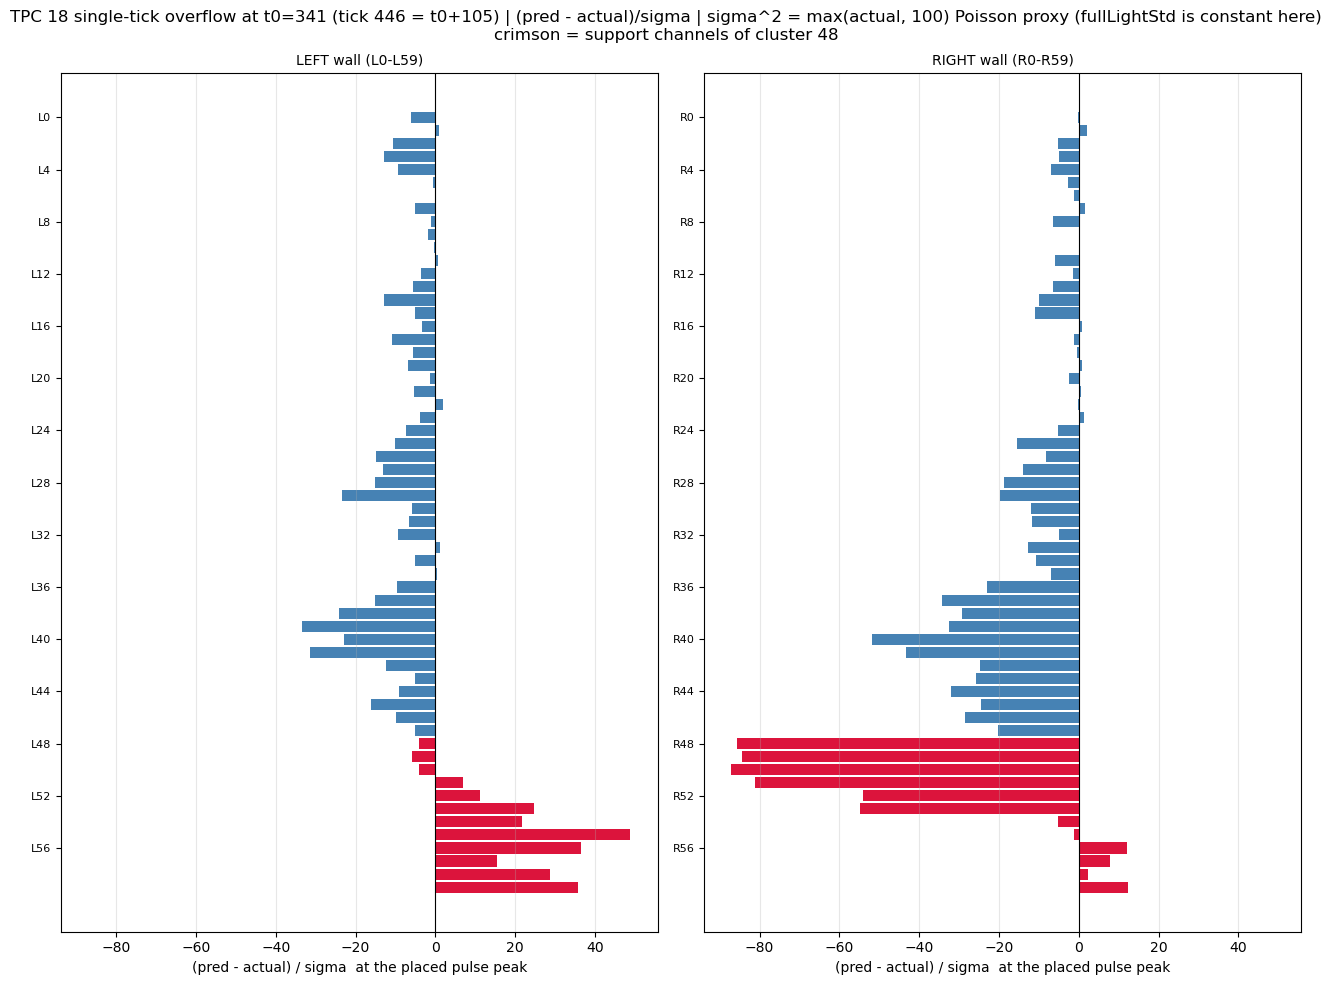

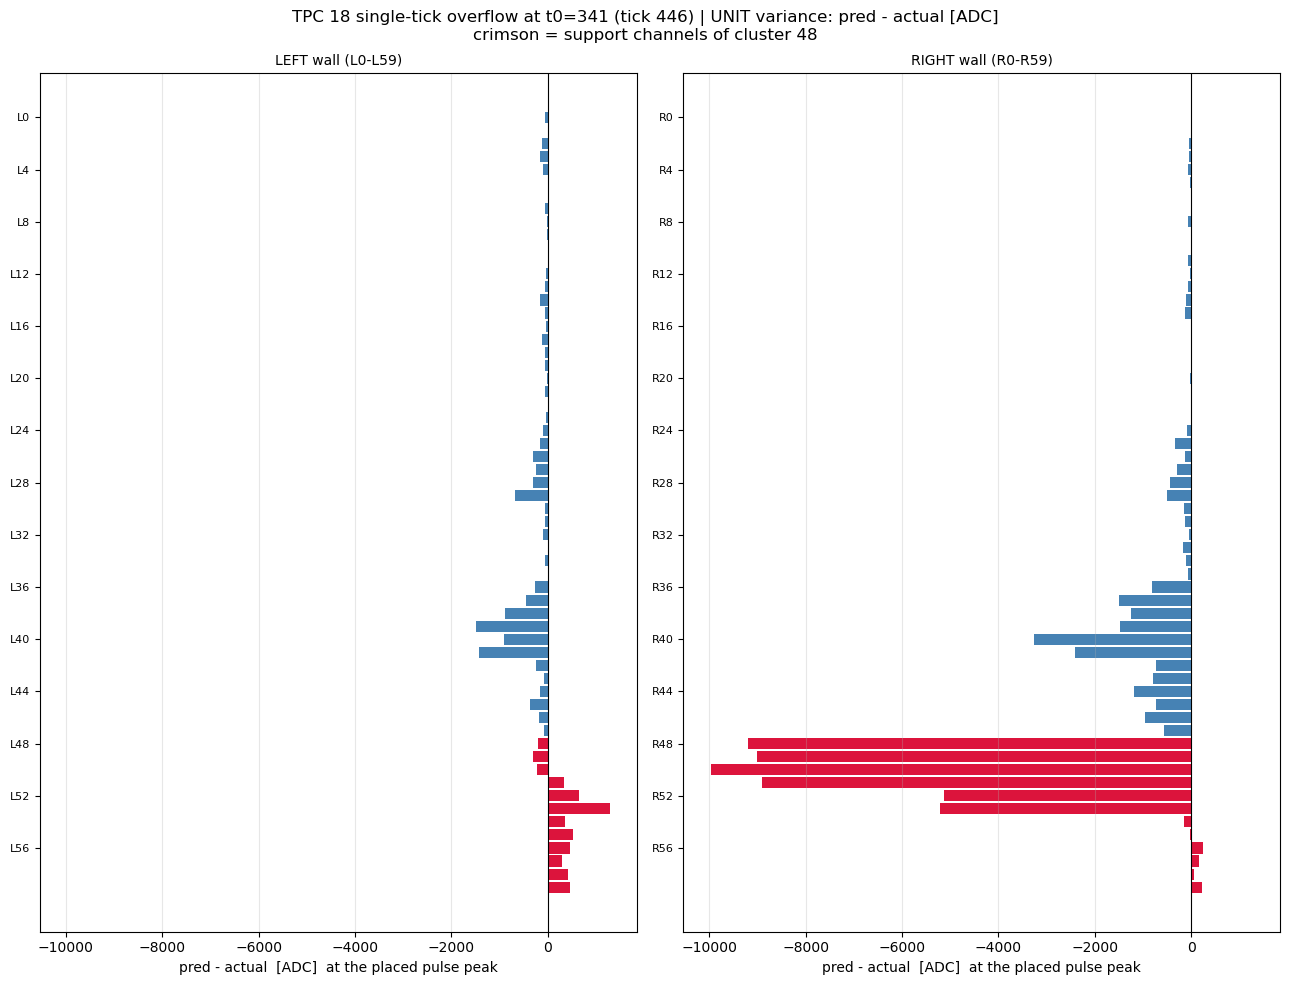


top-12 overflow channels at tick 446 (variance-normalized):
  ch  55 ( L55) SUPPORT (pred-actual)/sigma =    48.84 | raw =        512 ADC
  ch  56 ( L56) SUPPORT (pred-actual)/sigma =    36.56 | raw =        468 ADC
  ch  59 ( L59) SUPPORT (pred-actual)/sigma =    35.82 | raw =        454 ADC
  ch  58 ( L58) SUPPORT (pred-actual)/sigma =    28.73 | raw =        420 ADC
  ch  53 ( L53) SUPPORT (pred-actual)/sigma =    24.70 | raw =       1280 ADC
  ch  54 ( L54) SUPPORT (pred-actual)/sigma =    21.61 | raw =        359 ADC
  ch  57 ( L57) SUPPORT (pred-actual)/sigma =    15.50 | raw =        291 ADC
  ch 119 ( R59) SUPPORT (pred-actual)/sigma =    12.22 | raw =        220 ADC
  ch 116 ( R56) SUPPORT (pred-actual)/sigma =    12.01 | raw =        238 ADC
  ch  52 ( L52) SUPPORT (pred-actual)/sigma =    11.20 | raw =        644 ADC
  ch 117 ( R57) SUPPORT (pred-actual)/sigma =     7.80 | raw =        163 ADC
  ch  51 ( L51) SUPPORT (pred-actual)/sigma =     6.78 | raw =        343 ADC

si

In [16]:
# =====================================================================
# Single-tick overflow probe: if we place this cluster at t0, how much
# overflow does that cause per channel *at that placement's pulse peak*?
# Channels 0-59 = LEFT wall (L#), 60-119 = RIGHT wall (R#); bars run
# top-to-bottom in channel order; support channels of OV_LABEL = crimson.
# =====================================================================
import matplotlib.pyplot as plt

OV_TPC = int(WRONG_TPC_ID)      # TPC to inspect (18)
OV_LABEL = 48                   # cluster whose support channels to highlight (None = none)
OV_T0 = 341.0                   # the (wrong) placement t0 to probe
PEAK_OFFSET = 105               # placed pulse peaks at t0+105 (refine_t0_from_local_peak
                                # convention); set 0 to sample exactly at the t0 tick
EVAL_TICK = int(round(float(OV_T0))) + int(PEAK_OFFSET)
assert 0 <= EVAL_TICK < WVFM_LEN, f"EVAL_TICK {EVAL_TICK} out of range"

_ov_actual = np.asarray(fullLightWaveform, dtype=np.float64)[OV_TPC, :, EVAL_TICK]   # (120,)
_ov_pred = np.asarray(baseImage, dtype=np.float64)[OV_TPC, :, EVAL_TICK]             # (120,)
_ov_var = np.asarray(ns["fullLightStd"], dtype=np.float64)[OV_TPC, :, EVAL_TICK]
if bool(np.allclose(np.asarray(ns["fullLightStd"]).ravel()[0], ns["fullLightStd"])):
    _ov_var = np.maximum(_ov_actual, 100.0)
    _ov_var_label = "sigma^2 = max(actual, 100) Poisson proxy (fullLightStd is constant here)"
else:
    _ov_var_label = "variance-model fullLightStd"

ov_at_t0_sigma = (_ov_pred - _ov_actual) / np.sqrt(_ov_var)   # per-channel, single tick
ov_at_t0_raw = _ov_pred - _ov_actual                          # unit variance (plain ADC)

# support channels of the probed cluster in this TPC
_supp = np.zeros(120, dtype=bool)
if OV_LABEL is not None:
    _entry = ns["cluster_channel_support_cache"].get((int(OV_LABEL), OV_TPC))
    if _entry is not None:
        _supp[np.asarray(_entry["channel_indices"], dtype=int)] = True
        print(f"support channels of cluster {OV_LABEL} in TPC {OV_TPC} "
              f"({_entry['support_mode']}): {sorted(np.flatnonzero(_supp).tolist())}")
    else:
        print(f"NOTE: no support-cache entry for ({OV_LABEL}, {OV_TPC})")


def _overflow_bars(values, title, xlabel):
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 10), sharex=True)
    for ax, lo, side in ((axL, 0, "LEFT wall (L0-L59)"), (axR, 60, "RIGHT wall (R0-R59)")):
        ch = np.arange(lo, lo + 60)
        colors = ["crimson" if _supp[c] else "steelblue" for c in ch]
        ax.barh(np.arange(60), values[ch], color=colors, height=0.85)
        ax.set_yticks(np.arange(0, 60, 4))
        ax.set_yticklabels([f"{'L' if lo == 0 else 'R'}{i}" for i in range(0, 60, 4)], fontsize=8)
        ax.invert_yaxis()                        # channel 0 at the TOP
        ax.axvline(0.0, color="k", lw=0.8)
        ax.set_title(side, fontsize=10)
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", alpha=0.3)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


_overflow_bars(
    ov_at_t0_sigma,
    f"TPC {OV_TPC} single-tick overflow at t0={OV_T0:.0f} (tick {EVAL_TICK} = t0+{PEAK_OFFSET}) | "
    f"(pred - actual)/sigma | {_ov_var_label}\ncrimson = support channels of cluster {OV_LABEL}",
    "(pred - actual) / sigma  at the placed pulse peak",
)
_overflow_bars(
    ov_at_t0_raw,
    f"TPC {OV_TPC} single-tick overflow at t0={OV_T0:.0f} (tick {EVAL_TICK}) | "
    f"UNIT variance: pred - actual [ADC]\ncrimson = support channels of cluster {OV_LABEL}",
    "pred - actual  [ADC]  at the placed pulse peak",
)

# ---------- numbers for the pause-on-overflow check ----------
def _side_label(c):
    return f"L{c}" if c < 60 else f"R{c - 60}"

_order = np.argsort(ov_at_t0_sigma)[::-1]
print(f"\ntop-12 overflow channels at tick {EVAL_TICK} (variance-normalized):")
for c in _order[:12]:
    print(f"  ch {int(c):3d} ({_side_label(int(c)):>4}) "
          f"{'SUPPORT' if _supp[int(c)] else '       '} "
          f"(pred-actual)/sigma = {ov_at_t0_sigma[int(c)]:>8.2f} | "
          f"raw = {ov_at_t0_raw[int(c)]:>10.0f} ADC")

_pos = np.clip(ov_at_t0_sigma, 0, None)
print(f"\nsingle-tick overflow summary (positive side only):")
print(f"  support channels    : n={int(_supp.sum())} "
      f"sum={float(_pos[_supp].sum()):.1f} max={float(_pos[_supp].max()) if _supp.any() else 0.0:.1f} "
      f"n>3sigma={int((ov_at_t0_sigma[_supp] > 3.0).sum()) if _supp.any() else 0}")
print(f"  non-support channels: n={int((~_supp).sum())} "
      f"sum={float(_pos[~_supp].sum()):.1f} max={float(_pos[~_supp].max()):.1f} "
      f"n>3sigma={int((ov_at_t0_sigma[~_supp] > 3.0).sum())}")
